# Task

Summarize telecom payments by tariff, region and month: revenue, ARPU and unique subscribers.

# Data

In [1]:
import pandas as pd
import numpy as np

In [7]:
rng = np.random.default_rng(42)
n = 1000
df = pd.DataFrame({
    "subscriber_id": rng.integers(1, 301, n),
    "tariff": rng.choice(["Basic", "Standard", "Premium"], n, p=[0.5, 0.35, 0.15]),
    "region": rng.choice(["Astana", "Almaty", "Shymkent"], n),
    "month": rng.choice(["2026-07", "2026-08", "2026-09"], n),
})
df.head(20)

,subscriber_id,tariff,region,month
0,23,Standard,Shymkent,2026-08
1,151,Premium,Shymkent,2026-09
2,171,Basic,Astana,2026-09
3,220,Basic,Astana,2026-08
4,172,Standard,Astana,2026-08
5,57,Standard,Almaty,2026-08
6,111,Standard,Almaty,2026-07
7,134,Standard,Astana,2026-07
8,296,Standard,Almaty,2026-09
9,160,Standard,Astana,2026-08


In [8]:
base_fee = {"Basic": 2500, "Standard": 5000, "Premium": 9000}
df["fee"] = df["tariff"].map(base_fee) + rng.normal(0, 300, n).round()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subscriber_id  1000 non-null   int64  
 1   tariff         1000 non-null   str    
 2   region         1000 non-null   str    
 3   month          1000 non-null   str    
 4   fee            1000 non-null   float64
dtypes: float64(1), int64(1), str(3)
memory usage: 39.2 KB


In [14]:
df['subscriber_id'].nunique()

284

In [9]:
df.head(20)

,subscriber_id,tariff,region,month,fee
0,23,Standard,Shymkent,2026-08,4435.0
1,151,Premium,Shymkent,2026-09,9339.0
2,171,Basic,Astana,2026-09,2855.0
3,220,Basic,Astana,2026-08,2358.0
4,172,Standard,Astana,2026-08,5156.0
5,57,Standard,Almaty,2026-08,4935.0
6,111,Standard,Almaty,2026-07,5073.0
7,134,Standard,Astana,2026-07,4656.0
8,296,Standard,Almaty,2026-09,5187.0
9,160,Standard,Astana,2026-08,4508.0


# Analysis

In [15]:
df.groupby('tariff')['fee'].sum()

tariff
Basic       1202571.0
Premium     1357021.0
Standard    1825624.0
Name: fee, dtype: float64

In [16]:
df.groupby('tariff')['fee'].agg(['sum', 'mean', 'count'])

,sum,mean,count
tariff,,,
Basic,1202571.0,2489.795031,483
Premium,1357021.0,8986.894040,151
Standard,1825624.0,4988.043716,366


In [19]:
by_tariff = df.groupby('tariff').agg(
    revenue=('fee', 'sum'),
    payments=('fee', 'count'),
    subscribers=('subscriber_id', 'nunique'),
)
by_tariff['arpu'] = (by_tariff['revenue'] / by_tariff['subscribers']).round()
by_tariff

,revenue,payments,subscribers,arpu
tariff,,,,
Basic,1202571.0,483,236,5096.0
Premium,1357021.0,151,116,11698.0
Standard,1825624.0,366,207,8819.0


In [20]:
by_region_month = df.groupby(['region', 'month']).agg(
    revenue=('fee', 'sum'),
    subscribers=('subscriber_id', 'nunique')
).reset_index()
by_region_month.head(9)

,region,month,revenue,subscribers
0,Almaty,2026-07,475585.0,93
1,Almaty,2026-08,540743.0,101
2,Almaty,2026-09,462531.0,79
3,Astana,2026-07,492727.0,87
4,Astana,2026-08,463111.0,86
5,Astana,2026-09,521600.0,93
6,Shymkent,2026-07,491444.0,98
7,Shymkent,2026-08,467081.0,89
8,Shymkent,2026-09,470394.0,86


# Result

In [21]:
import matplotlib.pyplot as plt

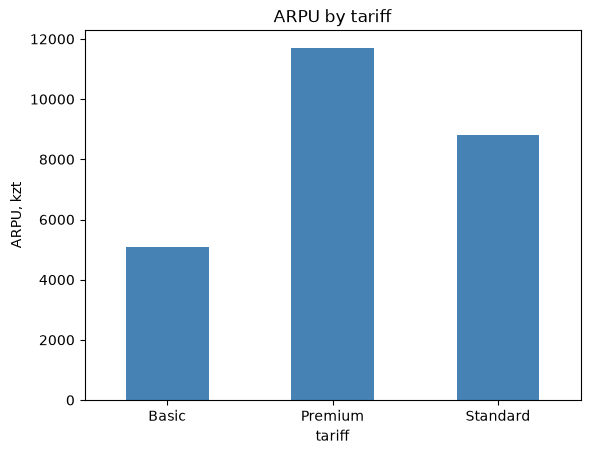

In [22]:
ax = by_tariff['arpu'].plot(kind='bar', color='steelblue')
ax.set_title('ARPU by tariff')
ax.set_ylabel('ARPU, kzt')
plt.xticks(rotation=0)
plt.show()

In [25]:
monthly = df.groupby('month')['subscriber_id'].nunique()
print(monthly)
print('Сумма по месяцам:', monthly.sum())
print('Уникальных за весь период:', df['subscriber_id'].nunique())

month
2026-07    193
2026-08    192
2026-09    194
Name: subscriber_id, dtype: int64
Сумма по месяцам: 579
Уникальных за весь период: 284


# What I learned

- first of all how to group rows
- grouped columns (region + month) carry more information than one by one
- it is important to distincguish count by lines and count by unique customers, results may vary dramatically